# Audit analytics: statistical analyses

This notebook plots the results of the statistical tests in `audit/statistics.py`. The functions are imported, not copied, so the notebook and `run_audit.py` always use the same logic.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

from audit.db import read_sql
from audit.statistics import benford_analysis, late_delivery_review_test

sns.set_theme(style='whitegrid')

## 1. Benford's law on payment amounts

Benford's law: in many natural financial datasets about 30% of amounts start with 1 and fewer than 5% with 9. Large deviations can point to invented or manipulated amounts, so auditors use it as a **screening test**.

In [2]:
benford_results, benford_summary = benford_analysis()
print(benford_summary)
benford_results

{'analysis': 'Benford first-digit test on payment amounts', 'n': 103720, 'statistic': 2012.8, 'p_value': 0.0, 'effect_size': 0.0142, 'conclusion': 'Marginal conformity (MAD 0.0142)'}


,digit,count,observed_pct,expected_pct,difference_pct
0,1,34483,33.25,30.10,3.14
1,2,14406,13.89,17.61,-3.72
2,3,11191,10.79,12.49,-1.70
3,4,9035,8.71,9.69,-0.98
4,5,8216,7.92,7.92,0.00
5,6,8222,7.93,6.69,1.23
6,7,6892,6.64,5.80,0.85
7,8,6009,5.79,5.12,0.68
8,9,5266,5.08,4.58,0.50


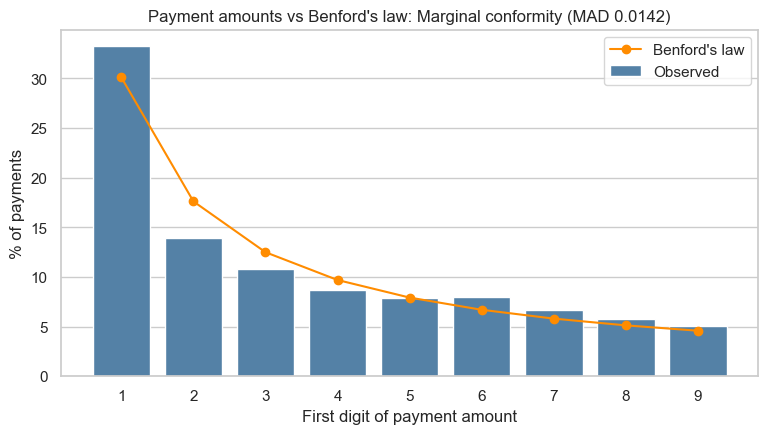

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=benford_results, x='digit', y='observed_pct', color='steelblue', label='Observed', ax=ax)
ax.plot(benford_results['digit'] - 1, benford_results['expected_pct'], 'o-', color='darkorange', label="Benford's law")
ax.set(xlabel='First digit of payment amount', ylabel='% of payments',
       title=f"Payment amounts vs Benford's law: {benford_summary['conclusion']}")
ax.legend()
plt.show()

**Interpretation.** The test uses 103,720 payments. The chi-square p-value is below 0.001, but with this many rows chi-square rejects almost any small difference, so we also look at the **MAD = 0.0142**: *marginal conformity* on Nigrini's scale. Digit 1 is over-represented (33.2% vs 30.1%) and digits 2–3 are under-represented. A plausible business reason: sellers set prices themselves (price points such as 19.90 or 69.90 BRL), so prices are not fully 'natural' numbers.

**Next audit step:** drill down. Run the same test per seller or per payment type and investigate the groups that deviate the most.

## 2. Do late deliveries get worse reviews? (Mann-Whitney U)

Review scores are whole numbers from 1 to 5 and not normally distributed, so we use the Mann-Whitney U test (it compares ranks) instead of a t-test.

In [4]:
review_test = late_delivery_review_test()
review_test

{'analysis': 'Mann-Whitney U: review score, late vs on-time delivery',
 'n': 96359,
 'statistic': 104438214.0,
 'p_value': 0.0,
 'effect_size': 0.638,
 'conclusion': 'Late (n=6,410) median 1, mean 2.27 vs on time (n=89,949) median 5, mean 4.29; large effect'}

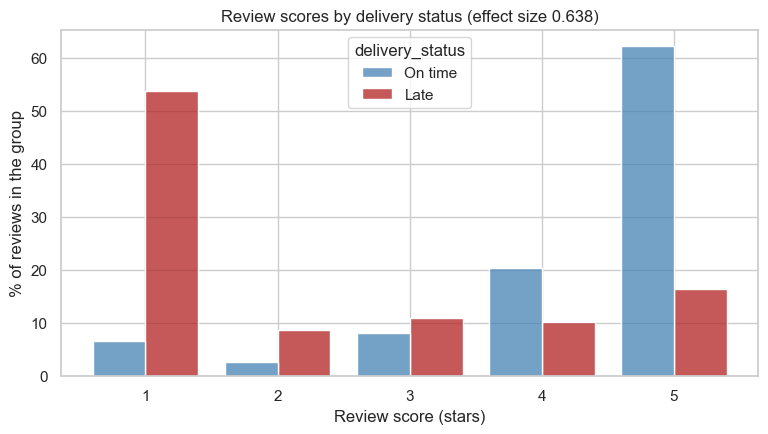

In [5]:
reviews = read_sql("""
    SELECT r.review_score,
           CASE WHEN date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date)
                THEN 'Late' ELSE 'On time' END AS delivery_status
    FROM order_reviews r JOIN orders o ON o.order_id = r.order_id
    WHERE o.order_delivered_customer_date IS NOT NULL
""")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=reviews, x='review_score', hue='delivery_status', discrete=True, stat='percent',
             common_norm=False, multiple='dodge', shrink=0.8, palette={'On time': 'steelblue', 'Late': 'firebrick'}, ax=ax)
ax.set(xlabel='Review score (stars)', ylabel='% of reviews in the group',
       title=f"Review scores by delivery status (effect size {review_test['effect_size']})")
plt.show()

**Interpretation.** Late orders (6,410 reviews) have a median of 1 star and a mean of 2.27, against a median of 5 and a mean of 4.29 for on-time orders (89,949 reviews). The p-value is below 0.001, and the effect size (rank-biserial correlation 0.64) is **large**: the difference is not just statistically significant, it matters.

**Audit relevance:** delivery performance is a key driver of customer satisfaction, so logistics controls (promised dates, carrier monitoring) belong in the audit plan. This is a correlation, not proof of causation.